# Module 6 — Agentic memory

Module 5 ends where a session ends. Everything it measured happened inside one
conversation and was gone when that conversation closed.

This module is about what survives it. It opens by asking the agent you built
two questions instead of one.

## Setup

The agent is module 5's, imported rather than rebuilt, and it reads the same
`config.ini`: a password written twice diverges.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import logging
import os
import sys
import warnings

# The memory library announces two things on every connection that are true and
# not ours to fix: a driver preview feature it touches, and the entity
# extractors it did not find because this notebook does not install them. Both
# are silenced here rather than left to scroll past the output that matters --
# and both are stated in the cells that would have shown them.
warnings.filterwarnings("ignore", module="neo4j_agent_memory.*")
warnings.filterwarnings("ignore", message=".*preview feature.*")
logging.getLogger("neo4j_agent_memory").setLevel(logging.ERROR)

# Module 5's package, and with it the agent you built. `pipelines/config.py`
# resolves config.ini against its own location, so the file stays in module 5
# and this notebook needs no copy of it.
sys.path.insert(0, "../05-graphrag")
sys.path.insert(0, ".")   # this module's own `memory/` package

from datetime import datetime

from neo4j import GraphDatabase
from pipelines.config import setting
from pipelines.react import SYSTEM, agent, tools_for
from pipelines.search import vector

driver = GraphDatabase.driver(setting("neo4j", "uri"),
                              auth=(setting("neo4j", "user"),
                                    setting("neo4j", "password")))
session = driver.session(database=setting("neo4j", "database"))

def run(query, **params):
    """Run one Cypher query and return its rows as a list of dictionaries."""
    return [dict(record) for record in session.run(query, **params)]


FIRST = "Who is the vendor of purchase order T25581?"
SECOND = "Which departments have they worked with?"

## 1. The agent does not know what it just said

One question, then the question you would actually ask next. Nothing else
changes: same agent, same eight tools, no arguments.

In [2]:
first = agent(session, FIRST)


  step 1: about_contracts({"purchase_orders": ["T25581"]})
     -> T25581: vendor J & D UNIFORMS, INC. (id vendor:Rcontracts:22765377V; 5 contracts across 7 departments: CHICAGO DEPARTMENT OF AVIATION, CHICAGO DEPARTMENT OF TRANSPORTATION, CHICAGO POLICE DEPARTMENT, DEPARTMENT OF FINANCE, DEPARTMENT OF PROCUREMENT SERVICES, DEPT OF GENERAL SERVICES, MAYORS OFFICE OF WORKFORCE DEVELOPMENT); department CHICAGO DEPARTMENT OF AVIATION, CHICAGO DEPARTMENT OF TRANSPORTATION, CHICAGO POLICE DEPARTMENT, DEPARTMENT OF PROCUREMENT SERVICES, DEPT OF GENERAL SERVICES, MAYORS OFFICE OF WORKFORCE DEVELOPMENT; type Add Line Item, COMMODITIES, Term Agreement, Time Extension



  step 2: answer
   The vendor of purchase order T25581 is J & D UNIFORMS, INC.
   
   1 contracts:
   purchase_order=T25581  title="VARIOUS WORK AND BUSINESS UNIFORMS + T8200721101 VARIOUS WORK AND BUSINESS UNIFORMS"

[ 2 steps   2 tool calls   10,613 chars sent ]


### What just ran

Two tool calls, and the answer is right: the graph records one vendor name for
T25581, and that is the one it gives.

Before the next question, both halves of what did it — the loop, and everything
that loop can reach.

648x515, parses, inside the canvas, no loose ampersand, 1 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other


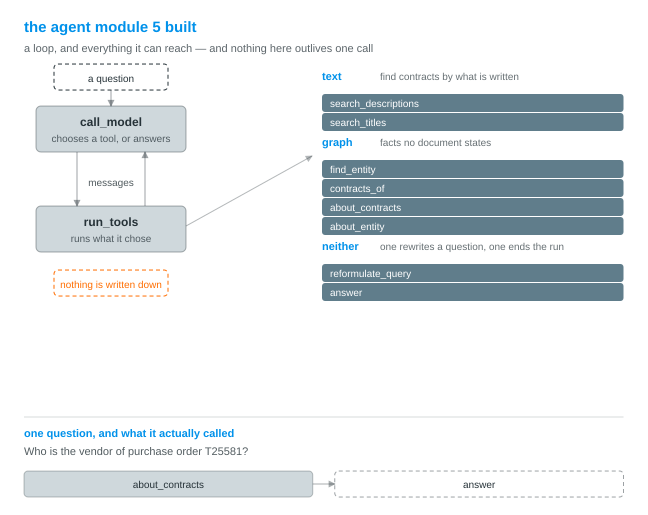

In [3]:
from IPython.display import SVG, display

from pictures import agent_picture, checks
from pipelines.react import tools_for

# The names come from what the model is shown, not from a list written here, and
# the example comes from the turn above: `agent_picture` checks the names
# against its own grouping and draws anything ungrouped in orange, so a tool
# added to module 5 cannot go unnoticed.
picture = agent_picture(
    [tool["function"]["name"] for tool in tools_for(session)],
    example={"question": FIRST,
             "calls": [step["tool"] for step in first["trace"]]})
print(checks(picture))
display(SVG(picture))

The orange box is this module. `messages` grows at every model call, carrying
the question and every tool result back up — and when LangGraph returns it is
gone. Nothing on either side of that loop writes anything down.

Now the question you would actually ask next.

In [4]:
second = agent(session, SECOND)


  step 1: find_entity({"name": "they"})
     -> no entity with contracts matches 'they'



  step 2: answer
   I need a specific company or department name to look up which departments it has worked with. "They" doesn't match any entity in the records — please tell me the name you have in mind.

[ 2 steps   2 tool calls   10,047 chars sent ]


It does not answer. It ran `find_entity` on the word **they**, treating the
pronoun as a company name, and asked you for the name instead.

Two tool calls either way, so the cost says nothing. What differs is that
`react.agent` builds its messages as `[SYSTEM, user]` at every call: the second
question starts from an empty conversation, and "they" has no antecedent in it.

The first conversation did have a memory — the `messages` list, which grew at
every model call. It worked, and then LangGraph returned and it was gone.

**What would you keep from the first turn so that the second one works?**

*Both counts move with the services: with the embedding endpoint down, this same
first question has taken twelve model calls instead of two. Read the cells.*

## 2. A memory is a record, and the agent already produces it

The smallest answer to that question: keep what was asked, what was answered,
and how. Three fields, built here rather than imported, because what goes in
the record is the decision this module is about.

The cell below prints both sides: what the first turn's characters actually
were, and what we take forward.

In [5]:
def remember(question, turn):
    """What was asked, what came back, and which calls got there."""
    return {"asked":  question,
            "answer": turn["answer"],
            "calls":  [{"tool": step["tool"], "args": step["args"]}
                       for step in turn["trace"]]}


def recall(records):
    """The whole record, in order, as text for the system message."""
    def one(r):
        calls = ", ".join(f"{c['tool']}({json.dumps(c['args'])})"
                          for c in r["calls"])
        return (f"Earlier in this conversation you were asked: {r['asked']}\n"
                f"You answered: {r['answer']}\n"
                f"You reached that by calling: {calls}")
    return "\n\n".join(one(r) for r in records)


memory = [remember(FIRST, first)]
carried = recall(memory)

# `sent` counts every call, and every call re-sends the whole conversation plus
# the tool declarations -- which is why `x2` below, and why most of the total is
# the same text twice.
tools = json.dumps(tools_for(session))
result = next(step["result"] for step in first["trace"]
              if step["tool"] == "about_contracts")
calls = first["calls"]

print(f"turn 1 read {first['sent']:,} characters, in {calls} calls to the model:\n")
for label, size, times in (("the eight tool declarations", len(tools), calls),
                           ("the system prompt", len(SYSTEM), calls),
                           ("the question", len(FIRST), calls),
                           ("what about_contracts returned", len(result), 1)):
    total = size * times
    print(f"   {label:32} {size:>6,} x{times} = {total:>6,}"
          f"   {total / first['sent']:>4.0%}")

print(f"\nthe record we carry into turn 2 is {len(carried):,} of them:\n")
print("   " + carried.replace("\n", "\n   "))


turn 1 read 10,613 characters, in 2 calls to the model:

   the eight tool declarations       3,491 x2 =  6,982    66%
   the system prompt                 1,473 x2 =  2,946    28%
   the question                         43 x2 =     86     1%
   what about_contracts returned       599 x1 =    599     6%

the record we carry into turn 2 is 484 of them:

   Earlier in this conversation you were asked: Who is the vendor of purchase order T25581?
   You answered: The vendor of purchase order T25581 is J & D UNIFORMS, INC.
   
   1 contracts:
   purchase_order=T25581  title="VARIOUS WORK AND BUSINESS UNIFORMS + T8200721101 VARIOUS WORK AND BUSINESS UNIFORMS"
   You reached that by calling: about_contracts({"purchase_orders": ["T25581"]}), answer({"summary": "The vendor of purchase order T25581 is J & D UNIFORMS, INC.", "purchase_orders": ["T25581"]})


And the record itself. From it the answer can be reconstructed: what was asked,
what was said, and which tool was called with which argument.

In [6]:
import json


def clip(text, width):
    """One line, cut to `width`, and saying so when it was cut.

    Every printed answer in this notebook is longer than a terminal line. A
    plain slice ends mid-word and reads like the model stopped there -- which
    in a lesson about what the model saw is exactly the wrong impression.
    """
    one = " ".join(str(text).split())
    return one if len(one) <= width else one[:width - 1].rstrip() + "\u2026"


for n, record in enumerate(memory, 1):
    print(f"--- record {n} ---")
    print(f"  asked  : {record['asked']}")
    print(f"  answer : {record['answer'].splitlines()[0]}")
    for call in record["calls"]:
        print(f"  call   : {call['tool']}({clip(json.dumps(call['args']), 70)})")
print(f"\n{len(json.dumps(memory)):,} characters in all")

--- record 1 ---
  asked  : Who is the vendor of purchase order T25581?
  answer : The vendor of purchase order T25581 is J & D UNIFORMS, INC.
  call   : about_contracts({"purchase_orders": ["T25581"]})
  call   : answer({"summary": "The vendor of purchase order T25581 is J & D UNIFORMS, I…)

481 characters in all


Now the same second question, with that text appended to the system message and
nothing else changed.

In [7]:
second_with_memory = agent(session, SECOND, system=SYSTEM + "\n\n" + str(memory))


  step 1: find_entity({"name": "J & D UNIFORMS, INC."})
     -> vendor:Rcontracts:22765377V | J & D UNIFORMS, INC. | 5 contracts



  step 2: about_entity({"id": "vendor:Rcontracts:22765377V"})
     -> vendor:Rcontracts:22765377V: 5 contracts, 1996-2005
        all 7 departments: CHICAGO DEPARTMENT OF AVIATION; CHICAGO DEPARTMENT OF TRANSPORTATION; CHICAGO POLICE DEPARTMENT; DEPARTMENT OF FINANCE; DEPARTMENT OF PROCUREMENT SERVICES; DEPT OF GENERAL SERVICES; MAYORS OFFICE OF WORKFORCE DEVELOPMENT
        contract types: Add Line Item; COMMODITIES; CONVERTED; Term Agreement; Time Extension



  step 3: answer
   J & D UNIFORMS, INC. has worked with 7 departments: Chicago Department of Aviation, Chicago Department of Transportation, Chicago Police Department, Department of Finance, Department of Procurement Services, Department of General Services, and Mayor's Office of Workforce Development.

[ 3 steps   3 tool calls   16,960 chars sent ]


It knows who *they* are, and answers: seven departments.

Now read the numbers below, because the obvious expectation is wrong.

In [8]:
for label, turn in (("no memory", second), ("with memory", second_with_memory)):
    print(f"{label:12} {turn['calls']:>3} model calls   {turn['sent']:>8,} chars")

print(f"\nthe record is {100 * len(carried) / first['sent']:.1f}% of what the first "
      f"turn read, and it was enough")

no memory      2 model calls     10,047 chars
with memory    3 model calls     16,960 chars

the record is 4.6% of what the first turn read, and it was enough


Memory did not make this cheaper: one extra call, and more characters. What it
bought is that the agent answered at all, and answered right — seven
departments, which is what the graph says.

So the claim is narrow and worth stating exactly: **a record a twentieth the size of one
turn turned a refusal into a correct answer.** Nothing here says memory makes an
agent cheaper, and nothing says it makes one right.

## 3. The same record, in a graph

Nothing above needs a graph. `memory` is a Python list, the second question
works, and the concept is complete: a record of what was asked and answered,
handed back.

It also dies with this kernel. Restart the notebook and the agent is back to
asking which contract you meant.

So the same thing again, written to Neo4j. The library is `neo4j-agent-memory`,
and its short-term layer is conversations and messages -- which is exactly what
`memory` holds. Note the database: **the memory does not go in the graph the
contracts live in.** It is a store of its own.

In [9]:
from neo4j_agent_memory import MemorySettings, Neo4jConfig, connect

from memory.embedder import CourseEmbedder

# The memory lives in a database of its own, beside the contracts in the same
# server -- decision 68. Read from the environment like every other connection
# in this course, so that pointing a run somewhere else never means editing a
# cell: the cell below empties whatever this names.
MEMORY_DB = os.environ.get("NEO4J_MEMORY_DATABASE", "kgtpmemory")
# One session per run: two people on one name clear each other's.
STAMP = datetime.now().strftime("%Y%m%d-%H%M%S")
SESSION = f"kgtp-m6-lesson-{STAMP}"

# `embedder` on the FIRST connection, or the store builds its vector indexes at
# the library's default 1536 and refuses the course model's 1024 ever after.
# Measured 11/11/2026, by doing it: the only way out is a new store.
store = await connect(
    MemorySettings(neo4j=Neo4jConfig(
        uri=setting("neo4j", "uri"),
        username=setting("neo4j", "user"),
        password=setting("neo4j", "password"),
        database=MEMORY_DB)),
    embedder=CourseEmbedder())

# Cleared first, or a second run leaves four messages, not two: a store appends.
await store.short_term.clear_session(SESSION)
await store.short_term.create_conversation(SESSION)
print(f"conversation {SESSION} open in {MEMORY_DB}, cleared of any earlier run")
print(f"embeddings: {CourseEmbedder().model}, {CourseEmbedder().dimensions} dimensions")

conversation kgtp-m6-lesson-20261124-184047 open in kgtpmemorye2e, cleared of any earlier run
embeddings: Qwen/Qwen3-Embedding-0.6B, 1024 dimensions


Before anything is written: whatever the last run left. A memory store only
appends, so the counts in this notebook — and the drawings of the graph — would
otherwise show every run at once.

Emptied with Cypher of ours rather than with the library's own call, for a
reason the cell says.

In [10]:
memory_session = driver.session(database=MEMORY_DB)

# Said out loud before anything is deleted. This cell empties a whole database,
# and which one it empties comes from the environment: a run pointed at the
# wrong name would take the lesson's memory with it, and the only warning would
# be the count printed afterwards.
print(f"about to empty: {MEMORY_DB}")

# Emptied with our own Cypher, and not with the library's `clear_session`,
# because that one does not reach everything: it removes a conversation's
# messages and leaves the traces and their tool calls behind. Measured
# 11/11/2026 -- 325 messages down to 3 while 150 `ToolCall` nodes did not move.
# Their documentation says the same: "no verified public DELETE route for
# reasoning steps, tool calls", and "conversation deletion is not proof that
# these records or extracted entities were removed".
#
# The schema stays. Dropping the database would take the vector indexes with
# it, and they are 1024 wide because the course model is: rebuilt by a client
# that forgot its embedder they come back at the library's default 1536, and
# every later connection is refused.
removed = memory_session.run("""
MATCH (n) WHERE NOT n:SchemaMigration
DETACH DELETE n
RETURN count(n) AS removed
""").single()["removed"]

kept = memory_session.run("""
SHOW INDEXES YIELD name, type WHERE type = 'VECTOR' RETURN count(*) AS n
""").single()["n"]

print(f"removed {removed} nodes left by earlier runs")
print(f"kept the schema: {kept} vector indexes, still 1024 wide")

about to empty: kgtpmemorye2e
removed 66 nodes left by earlier runs
kept the schema: 6 vector indexes, still 1024 wide


The messages go. The traces and their tool calls **stay** — `clear_session`
reaches the conversation and what hangs off it, and a `ReasoningTrace` carries
its own `session_id` rather than hanging off a conversation at all.

That is not a bug in the call; it is the shape of the store. The library's own
documentation says it plainly: *"no verified public DELETE route for reasoning
steps, tool calls"*, and *"conversation deletion is not proof that these records
or extracted entities were removed"*. So the tool statistics in section 6 count
every run this database has ever seen, and the ranking is what to read there,
not the totals.

`remember` wrote a dictionary. The same two fields go in as two messages: the
question as `user`, the answer as `assistant`.

In [11]:
# extract_entities and generate_embedding are off on purpose: they belong to the
# long-term layer, and left on they ask for a model this cell does not need.
PLAIN = dict(extract_entities=False, extract_relations=False,
             generate_embedding=False)

for record in memory:
    await store.short_term.add_message(SESSION, "user", record["asked"], **PLAIN)
    await store.short_term.add_message(SESSION, "assistant", record["answer"], **PLAIN)

print(f"{2 * len(memory)} messages written")

2 messages written


Two calls, and this is what they left behind — read back from the graph rather
than taken on the library's word.

860x384, parses, inside the canvas, no loose ampersand, 0 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other
no text over a box


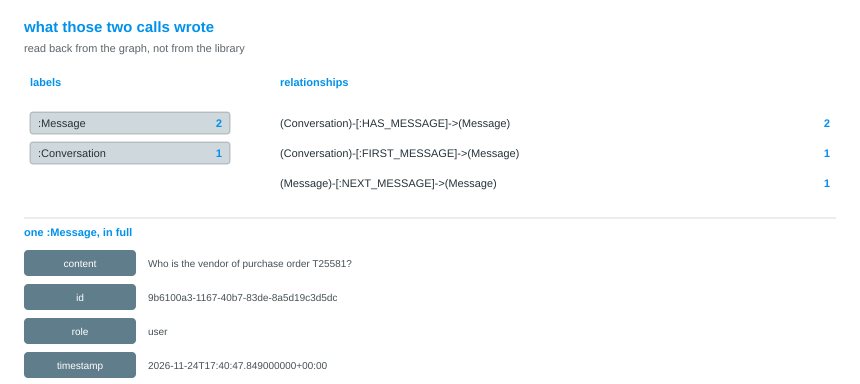

In [12]:
from IPython.display import SVG, display

from pictures import checks, text_over_box, written_picture

LABELS = """
CALL db.labels() YIELD label
CALL (label) { MATCH (n) WHERE label IN labels(n) RETURN count(n) AS n }
WITH label, n WHERE n > 0 AND label <> 'SchemaMigration'
RETURN label, n ORDER BY n DESC
"""

EDGES = """
MATCH (a)-[r]->(b)
RETURN type(r) AS type, labels(a)[0] AS from, labels(b)[0] AS to, count(r) AS n
ORDER BY n DESC
"""

# The node itself, not `keys(m)`: the figure shows each field with the value it
# holds, because `role` and `timestamp` as bare names leave the reader to guess
# what goes in them. The first message of the session, and the embedding is
# dropped -- it is 1024 numbers and not something to read.
SAMPLE = "MATCH (m:Message) RETURN m ORDER BY m.timestamp LIMIT 1"
message = memory_session.run(SAMPLE).single()["m"]

picture = written_picture(
    [dict(row) for row in memory_session.run(LABELS)],
    [dict(row) for row in memory_session.run(EDGES)],
    {"label": "Message",
     "fields": {k: v for k, v in sorted(dict(message).items())
                if k != "embedding"}})
print(checks(picture))
print(text_over_box(picture))
display(SVG(picture))

Four properties on a message — `id`, `role`, `content`, `timestamp` — and the
sequence in the relationships rather than in a counter.

Two of those edges are not in the documentation. The pages that describe this
layer name `HAS_MESSAGE` and stop; `FIRST_MESSAGE` and `NEXT_MESSAGE` are in the
data, and the order of a conversation turns out to live in a linked list nobody
wrote about. The graph is the authority, which is the reason this cell reads it
instead of drawing a schema from the docs.

Now the part the Python list cannot do. A **new client**, as if the notebook had
been restarted and the conversation reopened tomorrow:

In [13]:
reopened = await connect(
    MemorySettings(neo4j=Neo4jConfig(
        uri=setting("neo4j", "uri"),
        username=setting("neo4j", "user"),
        password=setting("neo4j", "password"),
        database=MEMORY_DB)),
    embedder=CourseEmbedder())

conversation = await reopened.short_term.get_conversation(SESSION)

for message in conversation.messages:
    print(f"[{message.role}] {clip(message.content, 88)}")
await reopened.close()

[MessageRole.USER] Who is the vendor of purchase order T25581?
[MessageRole.ASSISTANT] The vendor of purchase order T25581 is J & D UNIFORMS, INC. 1 contracts: purchase_order…


Same questions, same answers — and still there after the client that wrote them
is gone. That is the only thing this section adds.

**Still short-term**, and persisting does not change that. The layer is defined
by what it holds: the library's own documentation says *"short-term does not
mean in-process or automatically deleted"*. These records are one
conversation's history, and reading them back is reading one conversation.

## 4. Nine turns, and what you need was said in the first

Two turns fit in a prompt. Nine do not, and forty never will. So `recall` has to
**choose** — and this section is four choices, one Cypher clause apart, on the
same conversation.

Turn 1 asks who supplies the uniforms. Turns 2 to 9 are somebody working: a
topic search, a count, a named vendor, a yes/no. Then one question that points
back to turn 1 and names no contract.

In [14]:
from memory.mentions import mentions_of

LONG = f"kgtp-m6-long-{STAMP}"
OPENING = "Who is the vendor of purchase order T25581?"

# Different shapes on purpose -- a topic search, a count, a named vendor, a
# yes/no, a purchase order -- because nine times the same question is a
# conversation nobody has. Two candidates were dropped: "who supplies janitorial
# services to the Police" and "which vendors work with Water Management" each
# spent the whole twelve-step budget and returned nothing, and a conversation
# carrying those would measure the agent's reach rather than its memory.
FILLER = [
    "Which contracts are for snow removal?",
    "How many contracts does the Chicago Department of Aviation award?",
    "What does WALSH/T J LAMBRECHT JV work on?",
    "Which departments buy office furniture?",
    "Find contracts about tree trimming.",
    "Does DEPAUL UNIVERSITY hold more than one contract with the city?",
    "What kind of work is purchase order 31956 for?",
    "Are there contracts for towing abandoned vehicles?",
]
POINTS_BACK = "And that uniform supplier — which departments has it worked with?"

await store.short_term.clear_session(LONG)
await store.short_term.create_conversation(LONG)

history = []
for number, question in enumerate([OPENING] + FILLER, 1):
    turn = agent(session, question, echo=False,
                 system=SYSTEM + "\n\n" + recall(history[-3:]))
    # The entities this turn touched, taken from its tool calls rather than from
    # its prose: `about_contracts` names the purchase order in an argument.
    #
    # They are mixed in origin -- T25581 comes from the question, by way of the
    # tool argument, and the vendor from a query against the domain graph -- and
    # they all hang off the ASSISTANT message. The question goes in with
    # `extraction_mode="skip"`, so a policy that searches by entity can only
    # ever return answers.
    named = mentions_of(turn, session)
    await store.short_term.add_message(LONG, "user", question,
                                       extraction_mode="skip", generate_embedding=True)
    await store.short_term.add_message(LONG, "assistant", turn["answer"] or "",
                                       extraction_mode="explicit",
                                       explicit_mentions=named, generate_embedding=True)
    history.append(remember(question, turn))

    # The path, the names and the answer. The names rather than how many of
    # them: these are the entities the fourth policy will search by, and a turn
    # that names nothing is the silent gap `mentions_of` documents -- it reached
    # its answer by text search, so no MENTIONS edge can lead back to it.
    path = " -> ".join(step["tool"] for step in turn["trace"]
                       if step["tool"] != "answer") or "none"
    names = ", ".join(f"{ref.name} ({ref.type.lower()})" for ref in named)
    print(f"{number:>2}. {question}")
    print(f"    {turn['calls']:>2} model calls, {len(turn['trace'])} tools"
          f" | {clip(path, 70)}")
    print(f"    answer:      {clip(turn['answer'] or 'no answer', 91)}")
    print(f"    links to:    {clip(names, 91) or 'nothing -- reached by text search'}\n")

 1. Who is the vendor of purchase order T25581?
     2 model calls, 2 tools | about_contracts
    answer:      The vendor of purchase order T25581 is J & D UNIFORMS, INC. 1 contracts: purchase_order=T2…
    links to:    T25581 (object), J & D UNIFORMS, INC. (organization)



 2. Which contracts are for snow removal?
     7 model calls, 11 tools | search_descriptions -> search_descriptions -> reformulate_query -> se…
    answer:      Contracts for snow removal (and closely related snow/ice work) include the following purch…
    links to:    nothing -- reached by text search



 3. How many contracts does the Chicago Department of Aviation award?
     3 model calls, 3 tools | find_entity -> about_entity
    answer:      The Chicago Department of Aviation has awarded 3,522 contracts (spanning 1946–2047).
    links to:    Chicago Department of Aviation (organization)



 4. What does WALSH/T J LAMBRECHT JV work on?
     4 model calls, 4 tools | find_entity -> about_entity -> contracts_of
    answer:      WALSH/T J LAMBRECHT JV is a construction-aviation vendor with 7 contracts, all under the O…
    links to:    WALSH/T J LAMBRECHT JV (organization)



 5. Which departments buy office furniture?
     6 model calls, 8 tools | search_descriptions -> reformulate_query -> search_titles -> search_t…
    answer:      Based on the office furniture contracts found, the following departments buy office furnit…
    links to:    nothing -- reached by text search



 6. Find contracts about tree trimming.
     8 model calls, 14 tools | search_descriptions -> reformulate_query -> search_titles -> search_t…
    answer:      I found 48 contracts related to tree trimming, tree maintenance, tree removal, and vegetat…
    links to:    nothing -- reached by text search



 7. Does DEPAUL UNIVERSITY hold more than one contract with the city?
     4 model calls, 4 tools | find_entity -> about_entity -> contracts_of
    answer:      Yes — DePaul University holds 19 contracts with the City of Chicago, spanning 1996–2026. T…
    links to:    DEPAUL UNIVERSITY (organization)



 8. What kind of work is purchase order 31956 for?
     4 model calls, 4 tools | about_contracts -> search_titles -> search_descriptions
    answer:      Purchase order 31956 is a large construction contract ($3 million or above) awarded by the…
    links to:    31956 (object), CAPITOL CEMENT CO INC (organization)



 9. Are there contracts for towing abandoned vehicles?
     6 model calls, 10 tools | search_descriptions -> reformulate_query -> search_titles -> search_t…
    answer:      Yes — the City of Chicago has numerous towing contracts, though none are titled specifical…
    links to:    nothing -- reached by text search



Nine turns in the store. Each **answer** is linked to the entities its turn
touched — the question is stored with no links at all, so a policy that
searches by entity returns answers and never the questions that prompted them.

Now the four policies. Every one of them reads the memory graph and nothing
else, and the only thing that changes is how the rows are chosen.


In [15]:
QUESTION_VECTOR = await CourseEmbedder().embed(POINTS_BACK)

POLICIES = {
 "last 6 messages": ('''
    MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
    RETURN m.role AS role, m.content AS content
    ORDER BY m.timestamp DESC LIMIT 6''', {}),

 "closest 1 by cosine": ('''
    MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
    WHERE m.embedding IS NOT NULL
    WITH m, vector.similarity.cosine(m.embedding, $vector) AS score
    RETURN m.role AS role, m.content AS content ORDER BY score DESC LIMIT 1''', {}),

 "closest 6 by cosine": ('''
    MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
    WHERE m.embedding IS NOT NULL
    WITH m, vector.similarity.cosine(m.embedding, $vector) AS score
    RETURN m.role AS role, m.content AS content ORDER BY score DESC LIMIT 6''', {}),

 'mentions "uniform"': ('''
    MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
          -[:MENTIONS]->(e:Entity)
    WHERE toUpper(e.name) CONTAINS $word
    WITH DISTINCT m
    RETURN m.role AS role, m.content AS content
    ORDER BY m.timestamp LIMIT 6''', {"word": "UNIFORM"}),
}

RIGHT = "J & D UNIFORMS, INC."


def company(answer):
    """The first company an answer names, or its opening words if none."""
    return next((name for name in (RIGHT, "KALE UNIFORMS", "ENVIRONMENTAL AUTO")
                 if name in answer.upper()), clip(answer, 34))


# Each policy runs once, here, and what it produced is kept in `runs`: the
# drawing further down reads these results instead of asking the agent the same
# four questions a second time. That halved this section and removed a way for
# the table and the figure to disagree -- two runs of one policy can answer
# differently, and a reader has no way to tell which one the drawing shows.
runs = {}
print(f"{'recall policy':31} {'msgs':>4} {'chars':>6} {'in memory':>9}   the company it names")
for label, (cypher, extra) in POLICIES.items():
    rows = [dict(row) for row in memory_session.run(cypher, session=LONG,
                                                    vector=QUESTION_VECTOR, **extra)]
    carried = "\n\n".join(f"Earlier in this conversation ({r['role']}): {r['content']}"
                           for r in reversed(rows))
    turn = agent(session, POINTS_BACK, echo=False, system=SYSTEM + "\n\n" + carried)
    # The company printed rather than a verdict computed: which one it named is
    # the finding, and a True/False would hide it.
    runs[label] = {"rows": rows, "carried": carried,
                   "answer": " ".join((turn["answer"] or "no answer").split())}
    print(f"{label:31} {len(rows):>4} {len(carried):>6,} "
          f"{str(RIGHT.upper() in carried.upper()):>9}   {company(runs[label]['answer'])}")


recall policy                   msgs  chars in memory   the company it names


last 6 messages                    6  5,052     False   KALE UNIFORMS


closest 1 by cosine                1     76     False   KALE UNIFORMS


closest 6 by cosine                6  4,130      True   J & D UNIFORMS, INC.


mentions "uniform"                 1    230      True   J & D UNIFORMS, INC.


Four of them below, and the two that fail do not fail by saying so.

**Without turn 1 in memory, the agent goes looking for "uniform supplier" in the
graph and finds a different one.** Not a random contract: Kale Uniforms, another
City of Chicago uniform supplier, with its own purchase order and its own
departments. The answer is well formed, sourced, and about the wrong company —
and nothing in it says that the contract you asked about was never found.

The last six messages are the most characters any policy here carries, and still miss, because
the one message that mattered is nine turns back.

**The closest single message misses too.** The scores say why:

In [16]:
for row in memory_session.run('''
MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
WHERE m.embedding IS NOT NULL
WITH m, vector.similarity.cosine(m.embedding, $vector) AS score
RETURN score, m.role AS role, m.content AS content
ORDER BY score DESC LIMIT 6
''', session=LONG, vector=QUESTION_VECTOR):
    mark = "<-- the one that matters" if "UNIFORMS" in row["content"].upper() else ""
    print(f"{row['score']:.3f}  [{row['role']:9}] "
          f"{clip(row['content'], 52)} {mark}")

0.790  [user     ] Which departments buy office furniture? 
0.740  [user     ] Does DEPAUL UNIVERSITY hold more than one contract… 
0.725  [assistant] The vendor of purchase order T25581 is J & D UNIFOR… <-- the one that matters
0.720  [user     ] Which contracts are for snow removal? 
0.716  [assistant] Based on the office furniture contracts found, the… 
0.713  [user     ] What kind of work is purchase order 31956 for? 


The same graph after nine turns. The messages have entities now — the contracts
and the companies each turn was about, taken from the tool calls rather than
from the text.

Each of these is named by one message, because each turn asked about something
different. An entity named by **several** messages would be a single node they
share, and that is what makes this a graph rather than a log; this conversation
simply never comes back to the same company twice.

{'session': 'kgtp-m6-long-20261124-184047', 'messages': 18, 'entities': [{'name': '31956', 'messages': 1}, {'name': 'CAPITOL CEMENT CO INC', 'messages': 1}, {'name': 'Chicago Department of Aviation', 'messages': 1}, {'name': 'DEPAUL UNIVERSITY', 'messages': 1}, {'name': 'J & D UNIFORMS, INC.', 'messages': 1}], 'traces': 0, 'tool_calls': 0}
780x380, parses, inside the canvas, no loose ampersand, 2 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other


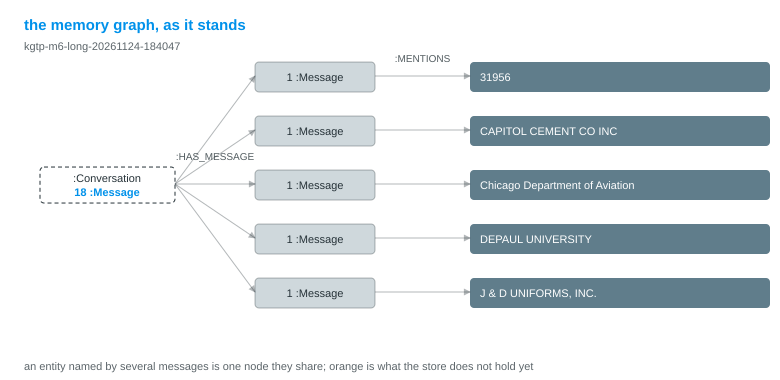

In [17]:
from memory.shape import shape_of

from pictures import memory_picture

shape = shape_of(memory_session, LONG)
print(shape)
picture = memory_picture(shape)
print(checks(picture))
display(SVG(picture))

And the four policies over the same nine turns, which the table above counts
but cannot show: the last six sit in a run at the end, cosine scatters, and the
entity policy takes one cell. An orange outline is the message a policy needed
and did not return.


1006x350, parses, inside the canvas, no loose ampersand, 0 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other
no text over a box


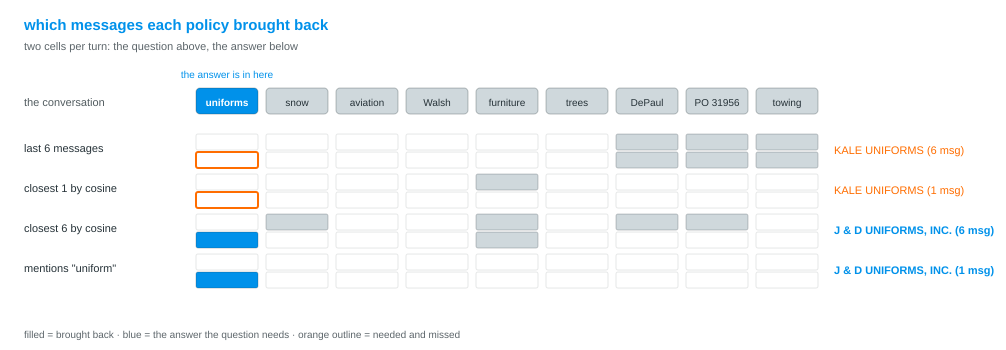

In [18]:
from pictures import recall_picture

# One row per policy, one cell per message. The subject of each turn comes from
# its question rather than from a list written here, and the cells a policy lit
# are the positions of the messages it returned -- so the row labelled
# "last 6 messages" lights six cells and cannot contradict its own name.
SUBJECTS = ["uniforms", "snow", "aviation", "Walsh", "furniture",
            "trees", "DePaul", "PO 31956", "towing"]

ordered = [row["content"] for row in memory_session.run("""
MATCH (:Conversation {session_id: $session})-[:HAS_MESSAGE]->(m:Message)
RETURN m.content AS content ORDER BY m.timestamp
""", session=LONG)]
position = {content: n for n, content in enumerate(ordered)}

# The results of the cell above, drawn. Nothing is asked again here.
lanes = {label: {"picked": sorted(position[r["content"]] for r in run["rows"]
                                  if r["content"] in position),
                 "named": company(run["answer"])}
         for label, run in runs.items()}

picture = recall_picture(SUBJECTS[:len(ordered) // 2], lanes, useful=1)
print(checks(picture))
print(text_over_box(picture))
display(SVG(picture))


The message that answers the question is **third**, behind office furniture and
a university lease.

Cosine matches the **shape of the question**. *"Which departments has it worked
with"* reads like *"which departments buy office furniture"*, and with the
message that actually answers it shares no words at all: that message is about a
vendor, and the question never says the vendor's name.

So the closest six work by carrying enough rows to include it anyway, not by
ranking it first. The more varied the conversation, the more ways it has to
resemble the wrong thing.

**Matching the word the question names ranks it first, and alone.** `J & D UNIFORMS, INC.` is mentioned by
one message here, so one row and the fewest characters of any policy answer the
question exactly. Not because entities beat vectors in general — because the
question names a thing, and a thing is something a graph matches rather than
approximates.

Those links cost no model. `mentions_of` reads the purchase order out of
`about_contracts`'s **argument**: the agent already said what it was looking
at.


## 5. The agent decides

Everything so far hands the agent its memory whether it wants it or not: we
choose when to read and which policy to read with, and it is shown a longer
system message without being told where the extra paragraph came from. It cannot
ask for memory, and it cannot decline it.

A tool can do both — but a tool needs a policy it can run on its own, and
neither of the two that work above is one.

Matching an entity by name needs the name, and the agent does not have it: that
is the whole point of the question it is asking. Cosine needs no name, carries
the right message, and ranks it **third**. So: narrow with the cheap retriever,
then spend one model call ranking the six rows it returned.


In [19]:
import re

from openai import OpenAI

from pipelines.models import NO_THINKING
from pipelines.react import LLM_KEY, LLM_URL

api = OpenAI(base_url=LLM_URL, api_key=LLM_KEY, timeout=180.0, max_retries=8)

PICK = ("You are given numbered messages from an earlier part of this "
        "conversation, and the question the user has just asked.\n"
        "Pick the messages that identify what the question refers to -- not "
        "messages on a similar subject.\n"
        "Answer with their numbers only, most useful first, separated by "
        "commas. No words, no explanation, no markdown. If none of them help, "
        "answer 0.\n"
        "Example of a valid answer: 3, 1")


def model_picks(candidates, question):
    """Ask the model which of these messages the question needs.

    Only a bare list of numbers is accepted. Pulling digits out of a prose
    reply rescued an answer once while this was being written, and the digits
    it rescued were the numbering of the model's own paragraph: a parse that
    cannot tell a choice from a bullet turns a format failure into a wrong
    answer nobody sees. So a reply that is not a list returns nothing, and the
    cell says so.
    """
    listed = "\n".join(f"{n}. [{c['role']}] {clip(c['content'], 240)}"
                        for n, c in enumerate(candidates, 1))
    reply = api.chat.completions.create(
        model=setting("llm", "model"), temperature=0, max_tokens=60,
        extra_body=NO_THINKING,
        messages=[{"role": "system", "content": PICK},
                  {"role": "user", "content": f"Messages:\n{listed}\n\nQuestion: {question}"}])
    said = (reply.choices[0].message.content or "").strip()
    if not re.fullmatch(r"\s*\d+(\s*,\s*\d+)*\s*", said):
        return said, None
    numbers = [int(n) for n in re.findall(r"\d+", said) if 0 < int(n) <= len(candidates)]
    return said, [candidates[n - 1] for n in dict.fromkeys(numbers)]

In [20]:
six = [dict(row) for row in memory_session.run(POLICIES["closest 6 by cosine"][0],
                                               session=LONG, vector=QUESTION_VECTOR)]
# The six as the model saw them, numbered, before its answer: the number it
# replies with means nothing to a reader who cannot see what it chose between.
print("what the model was shown:")
for n, row in enumerate(six, 1):
    print(f"  {n}. [{row['role']:9}] {clip(row['content'], 62)}")

said, chosen = model_picks(six, POINTS_BACK)
print(f"\nthe model answered: {said}")

if chosen is None:
    print("not a list of numbers: nothing selected, and nothing salvaged")
else:
    carried = "\n\n".join(f"Earlier in this conversation ({c['role']}): {c['content']}"
                           for c in reversed(chosen))
    turn = agent(session, POINTS_BACK, echo=False, system=SYSTEM + "\n\n" + carried)
    answer = " ".join((turn["answer"] or "no answer").split())
    named = next((name for name in (RIGHT, "KALE UNIFORMS", "ENVIRONMENTAL AUTO")
                  if name in answer.upper()), clip(answer, 34))
    print(f"\n{'closest 6, then the model picks 1':31} {len(chosen):>4} "
          f"{len(carried):>6,} {str(RIGHT.upper() in carried.upper()):>9}   {named}")
    for c in chosen:
        print(f"      [{c['role']:9}] {clip(c['content'], 62)}")

what the model was shown:
  1. [user     ] Which departments buy office furniture?
  2. [user     ] Does DEPAUL UNIVERSITY hold more than one contract with the c…
  3. [assistant] The vendor of purchase order T25581 is J & D UNIFORMS, INC. 1…
  4. [user     ] Which contracts are for snow removal?
  5. [assistant] Based on the office furniture contracts found, the following…
  6. [user     ] What kind of work is purchase order 31956 for?



the model answered: 3



closest 6, then the model picks 1    1    230      True   J & D UNIFORMS, INC.
      [assistant] The vendor of purchase order T25581 is J & D UNIFORMS, INC. 1…


One message, 230 characters against the 655 the closest six carried, and the
right company. The number the model answered is the row cosine ranked
**third** — the ordering cosine could not get right, the model did.

It fails differently from the policies above, and the failure is its own: it
answers prose instead of numbers. That happened while this cell was being
written, and was nearly rescued into a wrong answer by a parse that could not
tell a choice from a bullet. `model_picks` accepts a bare list of numbers and
nothing else.

This is the policy the tool below runs.


In [21]:
from memory.tool import RECALL, RECALL_LINE, recall_handler

print(RECALL["function"]["description"])
print()
print(RECALL_LINE)

What this conversation already established. Pass the question you were asked, in full and unchanged -- pronouns included. Use it whenever the question refers to something it does not name.

A question that refers to something without naming it -- "it", "that supplier", "the one you mentioned": recall first, passing the question itself.


It takes the **question**, not a name — and that is the whole of what this tool
got wrong first. Keyed on an entity name it was called on the right turn with
`about="uniform supplier"`, which is what the question says and not what the
entity is called: no row matched, and the agent went looking in the graph and
answered about a different uniform supplier. To pass the name as written it
would have needed the memory it was asking for.

So the handler takes the question and runs the policy above, unchanged.


In [22]:
from agent.catalogue import FULL, select
from agent.prompt import build

# `asked_about` is the record of what the tool was handed and what it gave back.
# Without it this cell could say the agent called `recall` and nothing about the
# argument it chose -- and the argument is the decision.
recall = recall_handler(memory_session, LONG, embed=vector, pick=model_picks,
                        log=(asked_about := []))

NEEDS_NOTHING = "How many contracts does the Chicago Department of Aviation award?"

# The ninth tool goes in beside the other eight, and the routing line beside the
# other routing lines. Nothing else about the agent changes.
decisions = []
for question in (NEEDS_NOTHING, POINTS_BACK):
    before = len(asked_about)
    turn = agent(session, question, echo=False,
                 tools=select(session, FULL) + [RECALL],
                 system=build(FULL) + "\n- " + RECALL_LINE,
                 extra_tools={"recall": recall})
    path = " -> ".join(step["tool"] for step in turn["trace"])

    print(f"question:  {question}")
    print(f"path:      {clip(path, 76)}")
    for call in asked_about[before:]:
        print(f"recall <-  {clip(call['question'], 76)}")
        for line in call["returned"].splitlines():
            print(f"recall ->  {clip(line, 76)}")
    if len(asked_about) == before:
        print("recall     not called")
    decisions.append({"question": question,
                      "path": [step["tool"] for step in turn["trace"]],
                      "recalled": asked_about[before] if len(asked_about) > before
                                  else None})
    print(f"answer:    {clip(turn['answer'] or 'no answer', 76)}\n")


question:  How many contracts does the Chicago Department of Aviation award?
path:      find_entity -> about_entity -> answer
recall     not called
answer:    The Chicago Department of Aviation has 3,522 contracts on record (spanning…



question:  And that uniform supplier — which departments has it worked with?
path:      recall -> find_entity -> about_entity -> answer
recall <-  And that uniform supplier — which departments has it worked with?
recall ->  [assistant] The vendor of purchase order T25581 is J & D UNIFORMS, INC. 1 c…
answer:    J & D UNIFORMS, INC. has worked with 7 departments: Chicago Department of A…



714x332, parses, inside the canvas, no loose ampersand, 0 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other
no text over a box


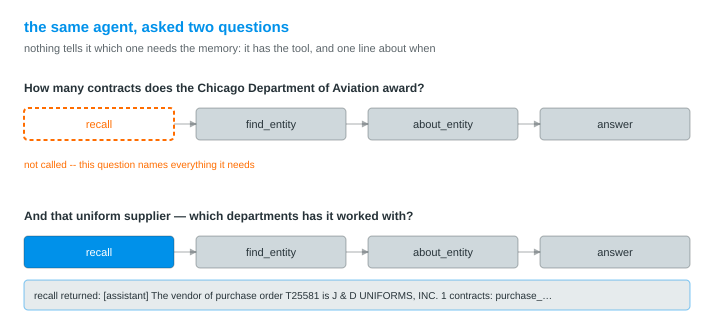

In [23]:
from pictures import decides_picture

# Both lanes on one grid, so the slot where `recall` is missing lines up with
# the slot where it was called. The two runs differ in one decision and the
# drawing has to show the decision, not two unrelated paths.
picture = decides_picture(decisions)
print(checks(picture))
print(text_over_box(picture))
display(SVG(picture))


It called `recall` on the question that refers to something it does not name,
and not on the one that names everything it needs. Nobody told it when: the
tool's description and one routing line are all it was given.

Two things about the handler are worth reading rather than taking on trust.

It runs the same cosine-then-model policy as the section above, so the agent is
not choosing between policies — only whether to look at all. Letting it choose
the policy too would measure a prompt about policies instead of a decision.

And when it finds nothing it says so and **stops there**. Its first version
added "it was not discussed, so look it up instead", the agent obeyed, searched,
and answered about the wrong company with sources attached. A tool reports; it
does not instruct. That sentence cost a correct answer, and it was written to be
helpful.


## 6. Remembering the path, not the answer

Everything so far remembers **what was said**. This section remembers **how it
was reached** — and the two turn out to be worth different amounts.

The store has a layer for it. A `ReasoningTrace` holds the steps and tool calls
of one turn, carries whether the turn succeeded, and can be retrieved by
similarity to a new task.

In [24]:
SHAPES = [
    ("A", "Which departments work with the vendor that holds purchase order 82547?"),
    ("A", "Which departments work with the vendor that holds purchase order 19486?"),
    ("B", "Which contracts are for snow removal?"),
    ("B", "Find contracts about tree trimming."),
]

TRACES = f"kgtp-m6-traces-{STAMP}"
answers = {}
written = {}   # question -> trace id, kept because a trace is not reliably
               # findable by its own task: `get_similar_traces` has a threshold

for shape, question in SHAPES:
    turn = agent(session, question, echo=False)
    trace = await store.reasoning.start_trace(TRACES, task=question)
    step = await store.reasoning.add_step(trace.id, action="the tool calls of one turn")
    for call in turn["trace"]:
        await store.reasoning.record_tool_call(step.id, call["tool"], call["args"] or {})
    # Not a judgement: the agent either called `answer` or spent its step budget.
    # `get_similar_traces` skips the failures by default, so this one boolean is
    # what keeps a path that never arrived from being offered as a procedure.
    await store.reasoning.complete_trace(trace.id, success=turn["answer"] is not None)
    answers[question] = turn["answer"] or ""
    written[question] = trace.id
    # Model calls and tool calls are different numbers: one call to the model
    # can ask for several tools at once, so a turn of 7 calls can hold 11 tools.
    print(f"[{shape}] {question}")
    print(f"     {turn['calls']} model calls, {len(turn['trace'])} tools, "
          f"{'answered' if turn['answer'] else 'ran out of steps'}")
    print(f"     {' -> '.join(s['tool'] for s in turn['trace'])}\n")

[A] Which departments work with the vendor that holds purchase order 82547?
     3 model calls, 3 tools, answered
     about_contracts -> about_entity -> answer



[A] Which departments work with the vendor that holds purchase order 19486?
     3 model calls, 3 tools, answered
     about_contracts -> about_entity -> answer



[B] Which contracts are for snow removal?
     7 model calls, 12 tools, answered
     search_descriptions -> search_descriptions -> reformulate_query -> search_titles -> search_titles -> search_titles -> search_titles -> search_titles -> search_titles -> search_titles -> search_titles -> answer



[B] Find contracts about tree trimming.
     4 model calls, 4 tools, answered
     search_descriptions -> reformulate_query -> search_titles -> answer



Two shapes of question, and two genuinely different paths: one goes straight at
the contract, the other searches text and reformulates.

Now a third question of the **first** shape, on a contract neither trace used.
Nothing is pasted in: the store is asked which past path resembles this task.

In [25]:
def template_of(trace):
    """The path a trace took, with its arguments made generic.

    The arguments are what make a trace the record of one turn; without them
    what is left is the order, which is the part that transfers. Consecutive
    repeats collapse: `search_titles` eight times in a row is one step of a
    procedure that was retried, not eight steps.
    """
    calls = [call for step in (trace.steps or []) for call in (step.tool_calls or [])]
    names = [f"{call.tool_name}({', '.join((call.arguments or {}).keys())})"
             for call in calls if call.tool_name != "answer"]
    return " then ".join(name for n, name in enumerate(names)
                         if n == 0 or name != names[n - 1])


NEW_TASK = "Which departments work with the vendor that holds purchase order T25581?"

for rank, found in enumerate(await store.reasoning.get_similar_traces(NEW_TASK, limit=3), 1):
    full = await store.reasoning.get_trace_with_steps(found.id)
    print(f"{rank}. {clip(found.task, 58)}")
    print(f"   {template_of(full)}\n")

1. Which departments work with the vendor that holds purchas…
   about_contracts(purchase_orders) then about_entity(id)

2. Which departments work with the vendor that holds purchas…
   about_contracts(purchase_orders) then about_entity(id)

3. Find contracts about tree trimming.
   search_descriptions(question) then reformulate_query(question) then search_titles(query, k)



The two traces of the same shape come back first, the other one third.

So retrieval of a **procedure** works by similarity — and the weakness measured
in section 4 is what makes it work. Cosine matched *"which departments has it
worked with"* to *"which departments buy office furniture"*, which was wrong
when the question needed a fact: the two share a shape and nothing else. A
procedure is the thing a shape is enough to choose.

Finding the path is not using it. So the same new question three times: with
nothing, with the **answer** the earlier turn gave, and with the **template**
retrieved above — which contains no answer at all.


In [26]:
best = (await store.reasoning.get_similar_traces(NEW_TASK, limit=1))[0]
template = template_of(await store.reasoning.get_trace_with_steps(best.id))
print(f"the template retrieved for this question:\n   {template}\n")

CARRIED = {
    "nothing": "",
    "the earlier answer": (f"Earlier in this conversation you were asked: "
                           f"{best.task}\nYou answered: {answers[best.task]}"),
    "the template": ("A question of this shape has been answered before, and "
                     "this is the order of tool calls that reached the answer:\n"
                     f"{template}\nFollow it unless something makes it wrong."),
}

paths = {}
print(f"{'carried':20} {'chars':>6} {'calls':>6}   path")
for label, carried in CARRIED.items():
    turn = agent(session, NEW_TASK, echo=False,
                 system=SYSTEM + (("\n\n" + carried) if carried else ""))
    path = " -> ".join(step["tool"] for step in turn["trace"]
                       if step["tool"] != "answer")
    paths[label] = [step["tool"] for step in turn["trace"]
                    if step["tool"] != "answer"]
    print(f"{label:20} {len(carried):>6,} {turn['calls']:>6}   {path}")

the template retrieved for this question:
   about_contracts(purchase_orders) then about_entity(id)

carried               chars  calls   path


nothing                   0      4   about_contracts -> find_entity -> about_entity


the earlier answer      339      4   about_contracts -> find_entity -> about_entity


the template            209      3   about_contracts -> about_entity


768x450, parses, inside the canvas, no loose ampersand, 1 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other
no text over a box


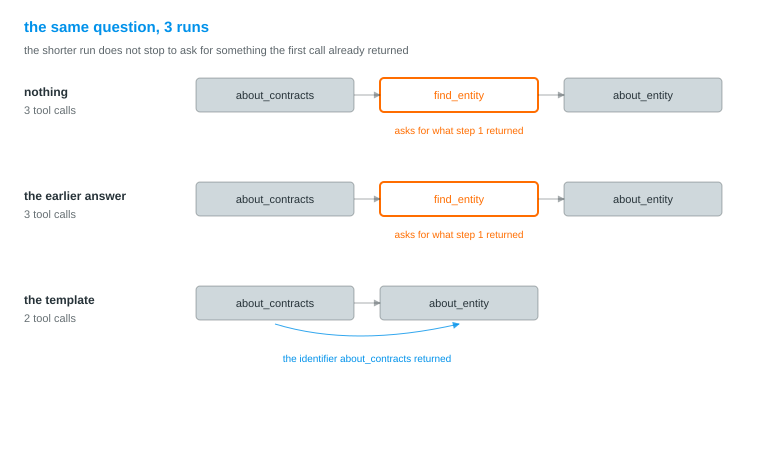

In [27]:
from pictures import procedure_picture

# `find_entity` is the step the template removes, and the identifier is what
# travels: `about_contracts` already returned it, so the run that knows the
# shape of the path does not stop to ask for it again.
picture = procedure_picture(paths, skipped="find_entity",
                            carried="the identifier about_contracts returned")
print(checks(picture))
print(text_over_box(picture))
display(SVG(picture))


The template takes a step out. The answer does not.

The step it takes out is `find_entity`: without the template the agent reads the
vendor's **name** from `about_contracts`, hands the name to `find_entity` to get
an identifier, then calls `about_entity`. The template tells it that
`about_contracts` already returned that identifier, so it goes straight there.

So what transfers is not a fact about Chicago. It is a fact about the **tools** —
that one call's output is already the next call's argument — and the template
carries it without carrying any answer. The middle row is the control that makes
that claim measurable: the earlier answer is more characters and buys nothing,
because the answer to one question does not help with another question of the
same shape.

What the template keeps is not everything the turn did. The traces are in the store with every call they made, so the two can be counted against each
other:


In [28]:
# What a procedure costs to store, against what the turn cost to run. No model
# is called here: the traces written above are read back by id and counted.
#
# By id, and not by similarity: `get_similar_traces` keeps only the successful
# ones, so a turn that spent its step budget cannot be found through it -- which
# is the right behaviour for retrieval and the wrong one for a table that is
# supposed to show what happened. Measured 19/11/2026, when it silently dropped
# a row.
#
# `get_tool_stats` was here before and said less. It counts every call this
# database has ever seen, so its totals grow with each run of the notebook, and
# its success rate was 100% for every tool -- a tool that returns rows has
# succeeded even when the rows are not what was asked for. That is a real limit
# of the layer, stated below, but it does not need a table of its own.
print(f"{'task':50} {'tool calls':>10} {'template':>9}  offered again")
for shape, question in SHAPES:
    full = await store.reasoning.get_trace_with_steps(written[question])
    calls = [call for step in (full.steps or []) for call in (step.tool_calls or [])]
    steps = len(template_of(full).split(" then ")) if full.success else 0
    print(f"{clip(question, 50):50} {len(calls):>10} {steps or '-':>9}"
          f"  {'yes' if full.success else 'no -- never reached an answer'}")


task                                               tool calls  template  offered again
Which departments work with the vendor that holds…          3         2  yes
Which departments work with the vendor that holds…          3         2  yes
Which contracts are for snow removal?                      12         4  yes
Find contracts about tree trimming.                         4         3  yes


The right-hand column is never larger than the middle one, and on the questions
that searched text it is smaller. What disappears are the **retries**:
`search_titles` several times in a row is one step of a procedure that was
repeated, not several steps of a procedure — the rule `template_of` applies, and
the reason a path can be reused at all.

A turn that never reaches an answer still stores its calls, and the last column
is where it would say so: `get_similar_traces` keeps the successful ones, so
that turn is never offered again. Which is the limit of this layer, worth saying
before anyone builds on it: a trace records what was called
and whether the turn ended with an answer. It does not record whether the answer
was **right** — nothing here could know that — so what is filtered out are the
paths that never arrived, not the ones that arrived somewhere wrong. The
library's tool statistics say the same from the other side: every tool succeeds
100% of the time, including the one that kept not finding what was asked for.


And the store once more, with the traces in it. Three drawings of one graph,
and between them the whole of what this notebook wrote into it: messages,
then the entities they name, then the paths the turns took.

4 traces, 22 tool calls, 0 messages -- this session wrote paths, not conversation
780x220, parses, inside the canvas, no loose ampersand, 1 edge label(s), none on a box, no boxes overlap, arrowheads clear of each other


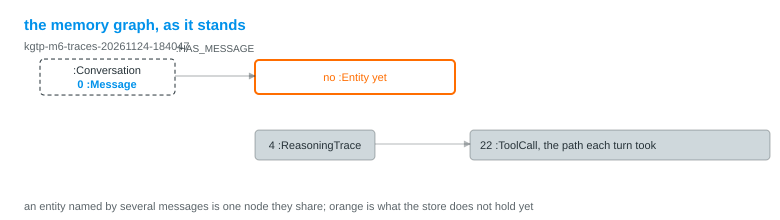

In [29]:
shape = shape_of(memory_session, TRACES)
print(f"{shape['traces']} traces, {shape['tool_calls']} tool calls, "
      f"{shape['messages']} messages -- this session wrote paths, not conversation")
picture = memory_picture(shape)
print(checks(picture))
display(SVG(picture))